# 1. Intro

Новый метод инициализации K-means можно сделать как смесь k-means++ и учёта плотности. Сначала берём первый центроид в самой плотной области данных, где у точки много соседей. Потом каждый следующий центроид выбираем среди точек, которые далеко от уже выбранных центроидов, но при этом находятся в достаточно плотной области. Если два центроида оказались слишком близко, один из них заменяем. Смысл в том, чтобы центроиды не попали в выбросы и не собрались все в одном плотном месте.

У Forgy инициализация простая: берём k случайных точек из данных как центроиды.

У Random Partition инициализация тоже простая: каждой точке случайно назначаем номер кластера, потом считаем центроиды этих случайных кластеров.

Кластеризацию можно использовать для ускорения KNN так. Сначала разбиваем обучающую выборку на кластеры, например с помощью K-means. Когда приходит новый объект, сначала смотрим, к каким центроидам кластеров он ближе. Потом ищем k ближайших соседей не среди всех обучающих точек, а только в самом перспективном кластере или в нескольких близких кластерах.

kd-tree — это дерево, которое рекурсивно делит пространство признаков на области. При поиске соседей мы спускаемся по дереву в нужную область. Если расстояние до границы соседней области больше, чем расстояние до уже найденного лучшего соседа, то всю эту область можно не проверять. Но в высокой размерности польза заметно падает.

# 2. Introduction

In [45]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, r2_score, mean_squared_error
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier, kneighbors_graph
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression

In [46]:
df_tmp1 = pd.read_json("data/train.json")
print("Train readed")
df_tmp2 = pd.read_json("data/test.json")
print("Test readed")

df = pd.concat([df_tmp1, df_tmp2], ignore_index=True)
df

Train readed
Test readed


,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
0,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
1,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
2,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
3,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
4,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124006,1.0,1,bd863d28a6b119ac3bc72d5f27b07f24,2016-04-26 16:09:55,BRAND NEW TO MARKET 1BDR \r107TH AND LEXINGTON...,150 EAST 107TH STREET,[],40.7925,6928108,-73.9454,453d46f8113e1f2c730c2ee5a4469c71,[https://photos.renthop.com/2/6928108_231eb983...,1700,158 EAST 107TH STREET,NaN
124007,1.0,2,9174b75c0cd978eb0e5aa93afbad754b,2016-04-21 05:06:19,Convertible 2BR apartment features a brand new...,E 33rd St.,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7456,6906674,-73.9797,2983e45f7e0ad87d677dacd13e362785,[https://photos.renthop.com/2/6906674_9fe899a8...,4195,141 E 33rd St.,NaN
124008,1.0,0,0,2016-04-20 01:31:52,"Let's get you in to see this $2,400/mo, recent...",Lexington Avenue,"[Dogs Allowed, Cats Allowed]",40.7416,6897967,-73.9829,e6472c7237327dd3903b3d6f6a94515a,[],2400,95 Lexington Avenue,NaN
124009,2.0,2,c90c010e5505365676538e64d02aa1e0,2016-04-08 02:26:45,CooperCooper.com :: Web ID #171357; Access 100...,Park Avenue,"[Doorman, Elevator, Cats Allowed, Dogs Allowed]",40.7485,6842183,-73.9800,6e5c10246156ae5bdcd9b487ca99d96a,[https://photos.renthop.com/2/6842183_b1fe51f4...,6895,41 Park Avenue,NaN


In [47]:
df = df[["bathrooms", "bedrooms", "features", "latitude", "longitude", "price", "interest_level", "manager_id"]]
df = df.loc[df["features"].str.len() > 0]
q1 = df["price"].quantile(0.01)
q99 = df["price"].quantile(0.99)
df = df.loc[df["price"].between(q1, q99)]
df

,bathrooms,bedrooms,features,latitude,longitude,price,interest_level,manager_id
0,1.0,1,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,-73.9539,2400,medium,a10db4590843d78c784171a107bdacb4
1,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,-73.9722,3800,low,955db33477af4f40004820b4aed804a0
2,1.0,2,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,-73.9625,3495,medium,c8b10a317b766204f08e613cef4ce7a0
4,1.0,0,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,-73.9743,2795,low,2c3b41f588fbb5234d8a1e885a436cfa
5,1.0,3,"[Doorman, Elevator, Loft, Dishwasher, Hardwood...",40.7348,-73.9865,7200,low,30a7951cfc21240e8c46b2d079d292e5
...,...,...,...,...,...,...,...,...
124005,1.0,2,"[Elevator, Cats Allowed, Dogs Allowed]",40.8248,-73.8554,1775,NaN,12c0a30e296faa0dfd422fe918d7d4f4
124007,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7456,-73.9797,4195,NaN,2983e45f7e0ad87d677dacd13e362785
124008,1.0,0,"[Dogs Allowed, Cats Allowed]",40.7416,-73.9829,2400,NaN,e6472c7237327dd3903b3d6f6a94515a
124009,2.0,2,"[Doorman, Elevator, Cats Allowed, Dogs Allowed]",40.7485,-73.9800,6895,NaN,6e5c10246156ae5bdcd9b487ca99d96a


In [48]:
q1 = df["latitude"].quantile(0.01)
q99 = df["latitude"].quantile(0.99)
df = df.loc[df["latitude"].between(q1, q99)]

q1 = df["longitude"].quantile(0.01)
q99 = df["longitude"].quantile(0.99)
df = df.loc[df["longitude"].between(q1, q99)]

df

,bathrooms,bedrooms,features,latitude,longitude,price,interest_level,manager_id
0,1.0,1,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,-73.9539,2400,medium,a10db4590843d78c784171a107bdacb4
1,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,-73.9722,3800,low,955db33477af4f40004820b4aed804a0
2,1.0,2,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,-73.9625,3495,medium,c8b10a317b766204f08e613cef4ce7a0
4,1.0,0,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,-73.9743,2795,low,2c3b41f588fbb5234d8a1e885a436cfa
5,1.0,3,"[Doorman, Elevator, Loft, Dishwasher, Hardwood...",40.7348,-73.9865,7200,low,30a7951cfc21240e8c46b2d079d292e5
...,...,...,...,...,...,...,...,...
124003,1.0,3,"[Doorman, Elevator, Pre-War, Laundry in Unit, ...",40.7639,-73.9808,5750,NaN,c23e16813063cb363bdd2904bd20d2d0
124007,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7456,-73.9797,4195,NaN,2983e45f7e0ad87d677dacd13e362785
124008,1.0,0,"[Dogs Allowed, Cats Allowed]",40.7416,-73.9829,2400,NaN,e6472c7237327dd3903b3d6f6a94515a
124009,2.0,2,"[Doorman, Elevator, Cats Allowed, Dogs Allowed]",40.7485,-73.9800,6895,NaN,6e5c10246156ae5bdcd9b487ca99d96a


In [49]:
mapping = {"high": 3, "medium": 2, "low": 1}
df["interest_level"] = df["interest_level"].map(mapping).fillna(0).astype(int)
df

,bathrooms,bedrooms,features,latitude,longitude,price,interest_level,manager_id
0,1.0,1,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,-73.9539,2400,2,a10db4590843d78c784171a107bdacb4
1,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,-73.9722,3800,1,955db33477af4f40004820b4aed804a0
2,1.0,2,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,-73.9625,3495,2,c8b10a317b766204f08e613cef4ce7a0
4,1.0,0,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,-73.9743,2795,1,2c3b41f588fbb5234d8a1e885a436cfa
5,1.0,3,"[Doorman, Elevator, Loft, Dishwasher, Hardwood...",40.7348,-73.9865,7200,1,30a7951cfc21240e8c46b2d079d292e5
...,...,...,...,...,...,...,...,...
124003,1.0,3,"[Doorman, Elevator, Pre-War, Laundry in Unit, ...",40.7639,-73.9808,5750,0,c23e16813063cb363bdd2904bd20d2d0
124007,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7456,-73.9797,4195,0,2983e45f7e0ad87d677dacd13e362785
124008,1.0,0,"[Dogs Allowed, Cats Allowed]",40.7416,-73.9829,2400,0,e6472c7237327dd3903b3d6f6a94515a
124009,2.0,2,"[Doorman, Elevator, Cats Allowed, Dogs Allowed]",40.7485,-73.9800,6895,0,6e5c10246156ae5bdcd9b487ca99d96a


In [50]:
df["features"] = df["features"].apply(lambda x: [item.replace(" ", "") for item in x])
df

,bathrooms,bedrooms,features,latitude,longitude,price,interest_level,manager_id
0,1.0,1,"[DiningRoom, Pre-War, LaundryinBuilding, Dishw...",40.7108,-73.9539,2400,2,a10db4590843d78c784171a107bdacb4
1,1.0,2,"[Doorman, Elevator, LaundryinBuilding, Dishwas...",40.7513,-73.9722,3800,1,955db33477af4f40004820b4aed804a0
2,1.0,2,"[Doorman, Elevator, LaundryinBuilding, Laundry...",40.7575,-73.9625,3495,2,c8b10a317b766204f08e613cef4ce7a0
4,1.0,0,"[Doorman, Elevator, FitnessCenter, LaundryinBu...",40.7439,-73.9743,2795,1,2c3b41f588fbb5234d8a1e885a436cfa
5,1.0,3,"[Doorman, Elevator, Loft, Dishwasher, Hardwood...",40.7348,-73.9865,7200,1,30a7951cfc21240e8c46b2d079d292e5
...,...,...,...,...,...,...,...,...
124003,1.0,3,"[Doorman, Elevator, Pre-War, LaundryinUnit, Do...",40.7639,-73.9808,5750,0,c23e16813063cb363bdd2904bd20d2d0
124007,1.0,2,"[Doorman, Elevator, LaundryinBuilding, Dishwas...",40.7456,-73.9797,4195,0,2983e45f7e0ad87d677dacd13e362785
124008,1.0,0,"[DogsAllowed, CatsAllowed]",40.7416,-73.9829,2400,0,e6472c7237327dd3903b3d6f6a94515a
124009,2.0,2,"[Doorman, Elevator, CatsAllowed, DogsAllowed]",40.7485,-73.9800,6895,0,6e5c10246156ae5bdcd9b487ca99d96a


In [51]:
features = ['Elevator', 'HardwoodFloors', 'CatsAllowed',
            'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee',
            'LaundryinBuilding', 'FitnessCenter', 'Pre-War',
            'LaundryinUnit', 'RoofDeck', 'OutdoorSpace',
            'DiningRoom', 'HighSpeedInternet', 'Balcony',
            'SwimmingPool', 'LaundryInBuilding',
            'NewConstruction', 'Terrace']
for col in features:
    df[col] = df["features"].apply(lambda x: int(col in x))
df.drop("features", axis=1, inplace=True)
df

,bathrooms,bedrooms,latitude,longitude,price,interest_level,manager_id,Elevator,HardwoodFloors,CatsAllowed,...,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
0,1.0,1,40.7108,-73.9539,2400,2,a10db4590843d78c784171a107bdacb4,0,1,1,...,0,0,0,1,0,0,0,0,0,0
1,1.0,2,40.7513,-73.9722,3800,1,955db33477af4f40004820b4aed804a0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1.0,2,40.7575,-73.9625,3495,2,c8b10a317b766204f08e613cef4ce7a0,1,1,0,...,1,0,0,0,0,0,0,0,0,0
4,1.0,0,40.7439,-73.9743,2795,1,2c3b41f588fbb5234d8a1e885a436cfa,1,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1.0,3,40.7348,-73.9865,7200,1,30a7951cfc21240e8c46b2d079d292e5,1,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124003,1.0,3,40.7639,-73.9808,5750,0,c23e16813063cb363bdd2904bd20d2d0,1,0,1,...,1,0,0,0,0,0,0,0,0,0
124007,1.0,2,40.7456,-73.9797,4195,0,2983e45f7e0ad87d677dacd13e362785,1,1,1,...,0,0,0,0,0,0,0,0,0,0
124008,1.0,0,40.7416,-73.9829,2400,0,e6472c7237327dd3903b3d6f6a94515a,0,0,1,...,0,0,0,0,0,0,0,0,0,0
124009,2.0,2,40.7485,-73.9800,6895,0,6e5c10246156ae5bdcd9b487ca99d96a,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [52]:
le = LabelEncoder()
mms_id = MinMaxScaler()
df["manager_id"] = le.fit_transform(df["manager_id"])
df["manager_id"] = mms_id.fit_transform(df[["manager_id"]])
df

,bathrooms,bedrooms,latitude,longitude,price,interest_level,manager_id,Elevator,HardwoodFloors,CatsAllowed,...,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
0,1.0,1,40.7108,-73.9539,2400,2,0.629966,0,1,1,...,0,0,0,1,0,0,0,0,0,0
1,1.0,2,40.7513,-73.9722,3800,1,0.583865,1,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1.0,2,40.7575,-73.9625,3495,2,0.788131,1,1,0,...,1,0,0,0,0,0,0,0,0,0
4,1.0,0,40.7439,-73.9743,2795,1,0.180481,1,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1.0,3,40.7348,-73.9865,7200,1,0.196665,1,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124003,1.0,3,40.7639,-73.9808,5750,0,0.763610,1,0,1,...,1,0,0,0,0,0,0,0,0,0
124007,1.0,2,40.7456,-73.9797,4195,0,0.170427,1,1,1,...,0,0,0,0,0,0,0,0,0,0
124008,1.0,0,40.7416,-73.9829,2400,0,0.902648,0,0,1,...,0,0,0,0,0,0,0,0,0,0
124009,2.0,2,40.7485,-73.9800,6895,0,0.427170,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [53]:
X_train, X_test = train_test_split(df, random_state=21, test_size=0.25)

# 3. K-means

In [54]:
class K_Means:
    def __init__(self, n_clusters=8, max_iter=300, tol=1e-4, random_state=21):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    @staticmethod
    def _d2(X, C):
        return ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = X.shape[0]
        rng = np.random.default_rng(self.random_state)

        idx = rng.choice(n, size=self.n_clusters, replace=False)
        centers = X[idx].copy()

        for _ in range(self.max_iter):
            d2 = self._d2(X, centers)
            labels = d2.argmin(axis=1)

            new_centers = centers.copy()
            for k in range(self.n_clusters):
                mask = labels == k
                if mask.any():
                    new_centers[k] = X[mask].mean(axis=0)
                else:
                    new_centers[k] = X[np.argmax(d2[np.arange(n), labels])]

            shift = np.linalg.norm(new_centers - centers, axis=1).max()
            centers = new_centers
            if shift < self.tol:
                break

        d2 = self._d2(X, centers)
        labels = d2.argmin(axis=1)

        self.cluster_centers_ = centers
        self.labels_ = labels
        self.inertia_ = float(d2[np.arange(n), labels].sum())
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self._d2(X, self.cluster_centers_).argmin(axis=1)



In [55]:
def distortion(X, labels, centers):
    X = np.asarray(X, dtype=float)
    centers = np.asarray(centers, dtype=float)
    labels = np.asarray(labels)

    d = np.sqrt(((X - centers[labels]) ** 2).sum(axis=1))
    sse = float((d ** 2).sum())

    if len(np.unique(labels)) >= 2:
        sil = float(silhouette_score(X, labels))
    else:
        sil = float("nan")

    return {
        "distortion (SSE/n)": sse / len(X),
        "среднее расстояние": float(d.mean() * 111.0),
        "Silhouette": sil,
    }

In [56]:
coords_train = X_train[["longitude", "latitude"]].to_numpy(dtype=float)
coords_test  = X_test[["longitude", "latitude"]].to_numpy(dtype=float)

km = K_Means(n_clusters=30)
km.fit(coords_train)

train_labels = km.labels_
test_labels  = km.predict(coords_test)

print("Train:", distortion(coords_train, train_labels, km.cluster_centers_))
print("Test: ", distortion(coords_test, test_labels, km.cluster_centers_))

Train: {'distortion (SSE/n)': 4.36347658545846e-05, 'среднее расстояние': 0.587848581525874, 'Silhouette': 0.38988983063175336}
Test:  {'distortion (SSE/n)': 4.439698305996047e-05, 'среднее расстояние': 0.5910618689624831, 'Silhouette': 0.38758515910007707}


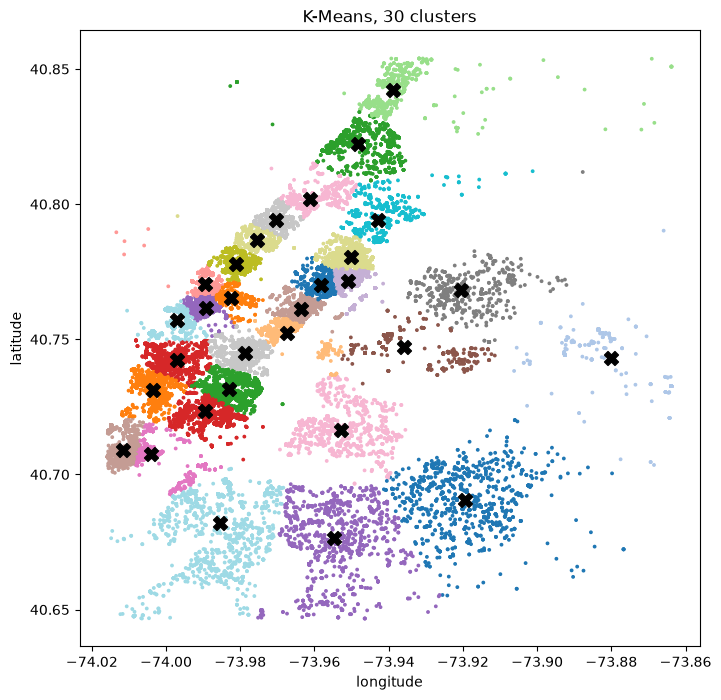

In [57]:
plt.figure(figsize=(8, 8))
plt.scatter(coords_train[:, 0], coords_train[:, 1],
            c=train_labels, s=3, cmap="tab20")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            c="black", marker="X", s=100)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title("K-Means, 30 clusters")
plt.show()

In [58]:
X_lasso_train = X_train.drop(columns=["price"]).copy()
X_lasso_test  = X_test.drop(columns=["price"]).copy()

X_lasso_train["cluster"] = train_labels
X_lasso_test["cluster"]  = test_labels

y_train = X_train["price"]
y_test  = X_test["price"]

mms = MinMaxScaler()
columns_to_scale = ['cluster', 'manager_id']
X_lasso_train[columns_to_scale] = mms.fit_transform(X_lasso_train[columns_to_scale])
X_lasso_test[columns_to_scale] = mms.transform(X_lasso_test[columns_to_scale])
lasso = Lasso(alpha=1.0, max_iter=10000, random_state=21)

lasso.fit(X_lasso_train, y_train)

coefs = pd.Series(lasso.coef_, index=X_lasso_train.columns)
coefs = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)
print(coefs)

longitude           -13155.521138
bathrooms              775.497580
bedrooms               669.027017
Doorman                544.046319
LaundryinUnit          473.055707
LaundryInBuilding     -472.556649
HardwoodFloors        -290.257403
cluster               -285.457606
HighSpeedInternet     -250.127633
Elevator               249.289698
DiningRoom             241.063368
FitnessCenter          185.791338
Terrace                170.492226
NoFee                 -164.356414
latitude               153.511945
LaundryinBuilding     -153.291632
SwimmingPool           134.868850
RoofDeck              -108.601905
interest_level         -98.732434
NewConstruction        -90.045714
Dishwasher              75.543473
manager_id              71.636590
Pre-War                -38.560445
OutdoorSpace           -20.223732
DogsAllowed             18.269350
Balcony                  3.803907
dtype: float64


In [59]:
sk_Km = KMeans(n_clusters=30, random_state=21)
sk_Km.fit(coords_train)

print("Train:", distortion(coords_train, sk_Km.labels_, sk_Km.cluster_centers_))
print("Test: ", distortion(coords_test, sk_Km.predict(coords_test), sk_Km.cluster_centers_))

Train: {'distortion (SSE/n)': 3.883209457999165e-05, 'среднее расстояние': 0.5728643022608924, 'Silhouette': 0.4248262110999983}
Test:  {'distortion (SSE/n)': 3.9159895323270426e-05, 'среднее расстояние': 0.5740281287485323, 'Silhouette': 0.42468894597401174}


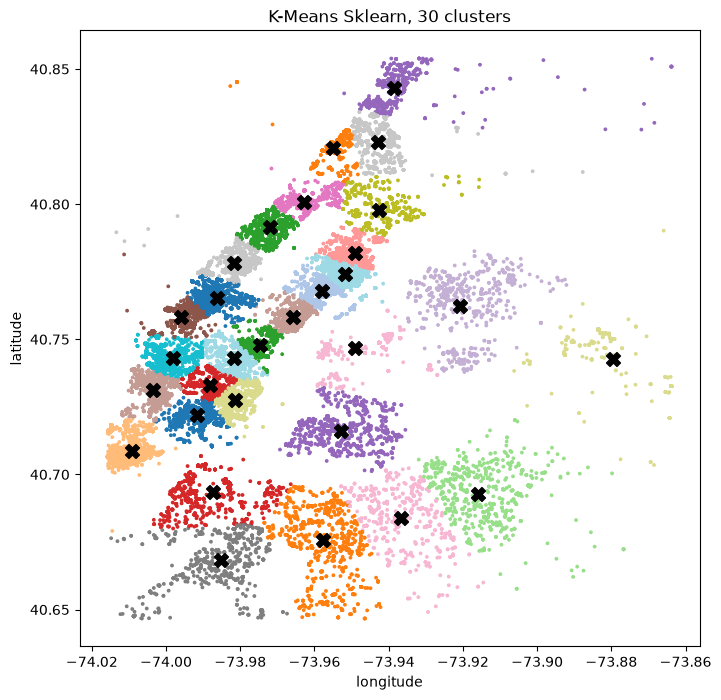

In [60]:
plt.figure(figsize=(8, 8))
plt.scatter(coords_train[:, 0], coords_train[:, 1],
            c=sk_Km.labels_, s=3, cmap="tab20")
plt.scatter(sk_Km.cluster_centers_[:, 0], sk_Km.cluster_centers_[:, 1],
            c="black", marker="X", s=100)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title("K-Means Sklearn, 30 clusters")
plt.show()

Вывод: примерно за такое же время выполнения sklearn дал результаты чуть лучше

# 4. DBScan

In [61]:
coords_train = X_train[["longitude", "latitude"]].to_numpy(dtype=float)
coords_test  = X_test[["longitude", "latitude"]].to_numpy(dtype=float)
y_train, y_test = X_train["price"], X_test["price"]

base_cols = [c for c in X_train.columns if c != "price"]
Xtr_base, Xte_base = X_train[base_cols].copy(), X_test[base_cols].copy()

In [62]:
def dbscan_assign(db, X):
    core = db.components_
    core_labels = db.labels_[db.core_sample_indices_]
    if len(core) == 0:
        return np.full(len(X), -1, dtype=int)
    nn = NearestNeighbors(n_neighbors=1, algorithm="ball_tree").fit(core)
    dist, idx = nn.kneighbors(np.asarray(X, dtype=float), n_neighbors=1)
    
    return np.where(dist[:, 0] <= db.eps, core_labels[idx[:, 0]], -1)

def distortion(X, labels):
    X = np.asarray(X, float)
    labels = np.asarray(labels)
    uniq = [l for l in np.unique(labels) if l != -1]
    mask = labels != -1
    if len(uniq) == 0 or mask.sum() == 0:
        return dict(n_clusters=0, noise=1.0, sse_per_n=np.nan, silhouette=np.nan)

    centers = np.array([X[labels == l].mean(axis=0) for l in uniq])
    lab_map = {l: i for i, l in enumerate(uniq)}
    idx = np.fromiter((lab_map[l] for l in labels[mask]),
                      dtype=int, count=int(mask.sum()))
    sse = float(((X[mask] - centers[idx]) ** 2).sum())

    sil = np.nan
    if len(uniq) >= 2 and mask.sum() > len(uniq):
        n_sample = min(2000, int(mask.sum()))
        if n_sample <= len(uniq):
            n_sample = None
        try:
            sil = float(silhouette_score(X[mask], labels[mask],
                                         sample_size=n_sample,
                                         random_state=0))
        except ValueError:
            sil = np.nan

    return dict(n_clusters=len(uniq),
                noise=round(float((~mask).sum() / len(X)), 3),
                sse_per_n=round(sse / len(X), 6),
                silhouette=round(sil, 3) if not np.isnan(sil) else np.nan)

def fit_lasso_with_cluster(tr_lbl, te_lbl, alpha=1.0):
    Xtr, Xte = Xtr_base.copy(), Xte_base.copy()
    Xtr["cluster"], Xte["cluster"] = tr_lbl, te_lbl
    mms_c = MinMaxScaler()
    Xtr[["cluster"]] = mms_c.fit_transform(Xtr[["cluster"]])
    Xte[["cluster"]] = mms_c.transform(Xte[["cluster"]])

    las = Lasso(alpha=alpha, max_iter=5000, random_state=21)
    las.fit(Xtr, y_train)
    pred = las.predict(Xte)
    coefs = pd.Series(las.coef_, index=Xtr.columns)
    coefs = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)
    
    return las, coefs, r2_score(y_test, pred), np.sqrt(mean_squared_error(y_test, pred))


In [63]:
param_grid = [
    (0.0010, 3), (0.0010, 5),
    (0.0015, 5), (0.0020, 3), (0.0020, 5), (0.0020, 10),
    (0.0030, 5), (0.0030, 10),
    (0.0050, 5), (0.0050, 10)
]

results = []
for eps, ms in param_grid:
    db = DBSCAN(eps=eps, min_samples=ms, algorithm="ball_tree").fit(coords_train)

    tr_lbl = db.labels_
    te_lbl = dbscan_assign(db, coords_test)
    st = distortion(coords_train, tr_lbl)

    _, _, r2, rmse = fit_lasso_with_cluster(tr_lbl, te_lbl)
    results.append(dict(
        eps=eps, ms=ms, n_clusters=st["n_clusters"],
        noise_tr=st["noise"],
        noise_te=round(float((te_lbl == -1).mean()), 3),
        sse_per_n=st["sse_per_n"], silhouette=st["silhouette"],
        Lasso_R2=round(float(r2), 4), Lasso_RMSE=round(float(rmse), 3)))
    print(results[-1], flush=True)

res_df = pd.DataFrame(results).sort_values("Lasso_R2", ascending=False)
print("\n", res_df.to_string(index=False))

{'eps': 0.001, 'ms': 3, 'n_clusters': 761, 'noise_tr': 0.011, 'noise_te': 0.018, 'sse_per_n': 0.000137, 'silhouette': -0.253, 'Lasso_R2': 0.6, 'Lasso_RMSE': 1025.207}
{'eps': 0.001, 'ms': 5, 'n_clusters': 563, 'noise_tr': 0.021, 'noise_te': 0.027, 'sse_per_n': 7.8e-05, 'silhouette': -0.149, 'Lasso_R2': 0.5995, 'Lasso_RMSE': 1025.886}
{'eps': 0.0015, 'ms': 5, 'n_clusters': 263, 'noise_tr': 0.008, 'noise_te': 0.011, 'sse_per_n': 0.000794, 'silhouette': -0.474, 'Lasso_R2': 0.6019, 'Lasso_RMSE': 1022.748}
{'eps': 0.002, 'ms': 3, 'n_clusters': 131, 'noise_tr': 0.003, 'noise_te': 0.004, 'sse_per_n': 0.001154, 'silhouette': -0.53, 'Lasso_R2': 0.5998, 'Lasso_RMSE': 1025.471}
{'eps': 0.002, 'ms': 5, 'n_clusters': 97, 'noise_tr': 0.004, 'noise_te': 0.006, 'sse_per_n': 0.001151, 'silhouette': -0.414, 'Lasso_R2': 0.5999, 'Lasso_RMSE': 1025.335}
{'eps': 0.002, 'ms': 10, 'n_clusters': 82, 'noise_tr': 0.01, 'noise_te': 0.013, 'sse_per_n': 0.001132, 'silhouette': -0.421, 'Lasso_R2': 0.5996, 'Lasso_RMS

In [64]:
best = res_df.iloc[0]
EPS, MS = float(best["eps"]), int(best["ms"])
print(f"BEST: eps={EPS}, min_samples={MS}, "
      f"n_clusters={int(best['n_clusters'])}, R2={best['Lasso_R2']}")

db_best = DBSCAN(eps=EPS, min_samples=MS, algorithm="ball_tree").fit(coords_train)
tr_lbl = db_best.labels_
te_lbl = dbscan_assign(db_best, coords_test)

print("Train:", distortion(coords_train, tr_lbl))
print("Test :", distortion(coords_test,  te_lbl))

BEST: eps=0.0015, min_samples=5, n_clusters=263, R2=0.6019
Train: {'n_clusters': 263, 'noise': 0.008, 'sse_per_n': 0.000794, 'silhouette': -0.474}
Test : {'n_clusters': 249, 'noise': 0.011, 'sse_per_n': 0.000793, 'silhouette': -0.488}


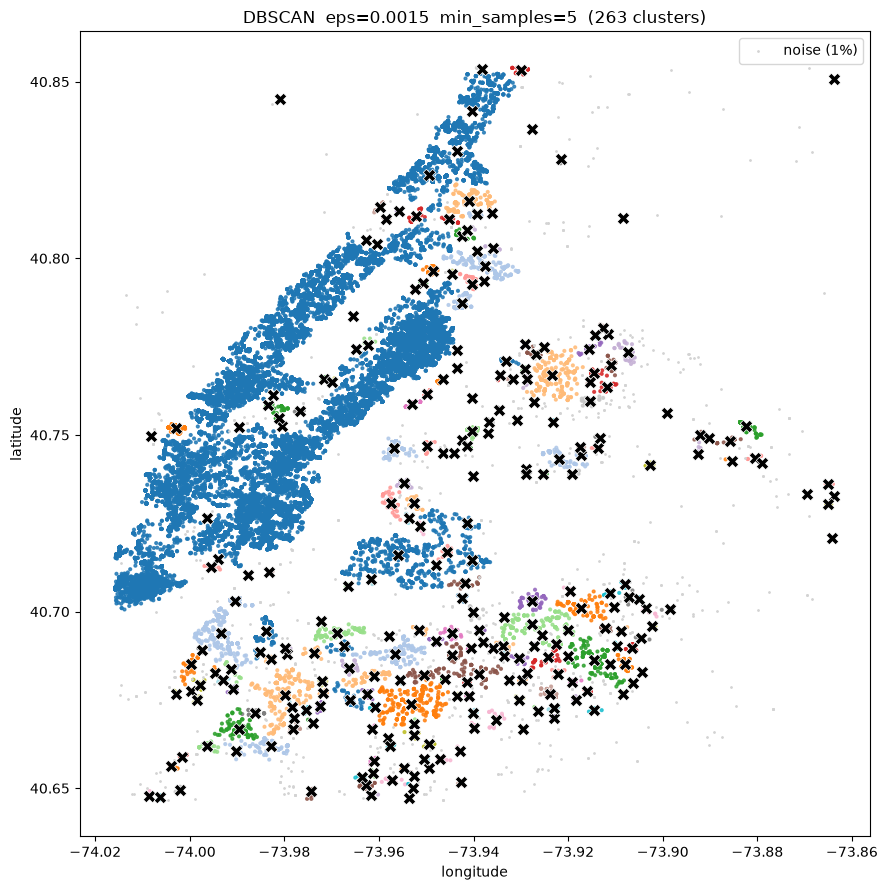

In [65]:
noise = tr_lbl == -1
plt.figure(figsize=(9, 9))
plt.scatter(coords_train[~noise, 0], coords_train[~noise, 1],
            c=tr_lbl[~noise], s=4, cmap="tab20", alpha=0.8)
plt.scatter(coords_train[noise, 0], coords_train[noise, 1],
            c="lightgray", s=1, label=f"noise ({noise.mean():.0%})")
centers = np.array([coords_train[tr_lbl == l].mean(axis=0)
                    for l in set(tr_lbl) - {-1}])
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=80,
            edgecolor="white", linewidth=0.5)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title(f"DBSCAN  eps={EPS}  min_samples={MS}  "
          f"({len(set(tr_lbl) - {-1})} clusters)")
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
lasso_db, coefs_db, r2_db, rmse_db = fit_lasso_with_cluster(tr_lbl, te_lbl)
print(f"Lasso + DBSCAN cluster: R2={r2_db:.4f} RMSE={rmse_db:.3f}")
print("\nFeature importance:")
print(coefs_db)

Lasso + DBSCAN cluster: R2=0.6019 RMSE=1022.748

Feature importance:
longitude           -11539.909096
cluster               -964.246891
bathrooms              770.087187
bedrooms               673.901143
Doorman                528.947514
LaundryinUnit          480.344139
LaundryInBuilding     -457.910781
HardwoodFloors        -299.619685
HighSpeedInternet     -257.353580
DiningRoom             243.490793
Elevator               238.253994
FitnessCenter          179.549175
NoFee                 -161.332159
LaundryinBuilding     -159.417851
Terrace                154.390808
RoofDeck              -111.661088
interest_level         -97.901491
SwimmingPool            89.818427
Dishwasher              72.758967
NewConstruction        -71.288645
manager_id              71.185277
Pre-War                -48.240467
DogsAllowed             20.883064
OutdoorSpace           -16.221699
dtype: float64


In [67]:
las_base = Lasso(alpha=1.0, max_iter=5000, random_state=21)
las_base.fit(Xtr_base, y_train)
pred_base = las_base.predict(Xte_base)
r2_base = r2_score(y_test, pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, pred_base))

sk_db = DBSCAN(eps=EPS, min_samples=MS).fit(coords_train)
print(f"sklearn DBSCAN: n_clusters={len(set(sk_db.labels_) - {-1})}, "
      f"noise={(sk_db.labels_ == -1).mean():.3f}")

sklearn DBSCAN: n_clusters=263, noise=0.008


In [68]:
tr_lbl_sk = sk_db.labels_
te_lbl_sk = dbscan_assign(sk_db, coords_test)

print("Train:", distortion(coords_train, tr_lbl_sk))
print("Test :", distortion(coords_test,  te_lbl_sk))

Train: {'n_clusters': 263, 'noise': 0.008, 'sse_per_n': 0.000794, 'silhouette': -0.474}
Test : {'n_clusters': 249, 'noise': 0.011, 'sse_per_n': 0.000793, 'silhouette': -0.488}


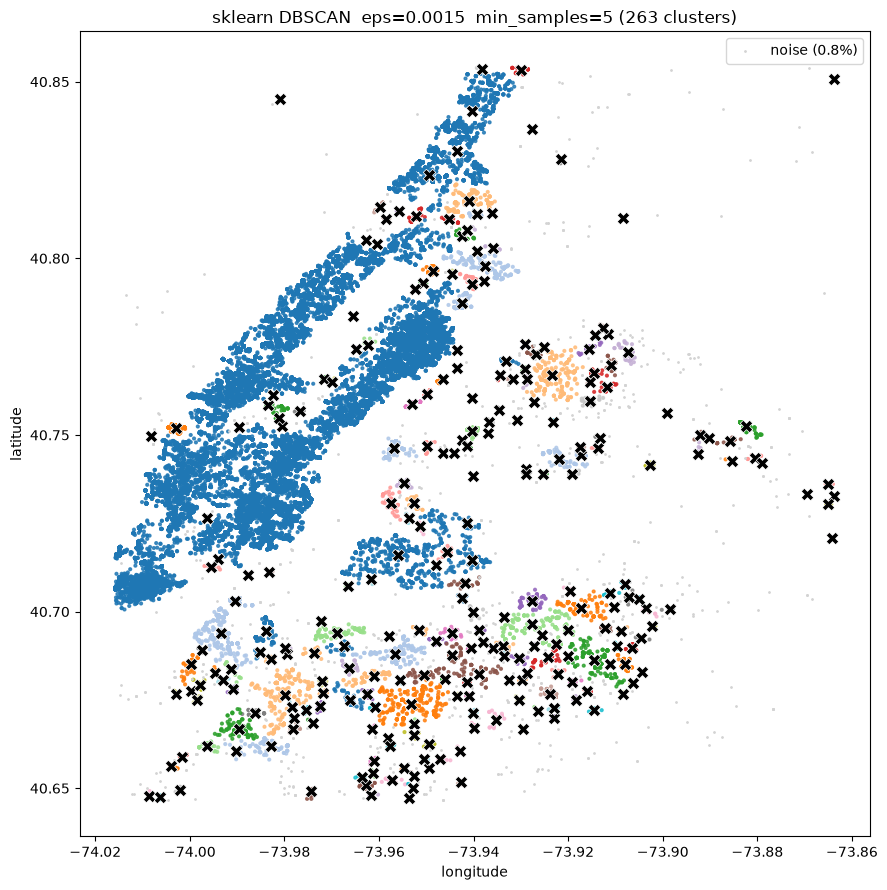

In [69]:
tr_lbl_sk = sk_db.labels_
noise = tr_lbl_sk == -1
plt.figure(figsize=(9, 9))
plt.scatter(coords_train[~noise, 0], coords_train[~noise, 1],
            c=tr_lbl_sk[~noise], s=4, cmap="tab20", alpha=0.8)
plt.scatter(coords_train[noise, 0], coords_train[noise, 1],
            c="lightgray", s=1, label=f"noise ({noise.mean():.1%})")
centers = np.array([coords_train[tr_lbl_sk == l].mean(axis=0)
                    for l in set(tr_lbl_sk) - {-1}])
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=80,
            edgecolor="white", linewidth=0.5)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title(f"sklearn DBSCAN  eps={EPS}  min_samples={MS} "
          f"({len(set(tr_lbl_sk) - {-1})} clusters)")
plt.legend()
plt.tight_layout()
plt.show()

Вывод: за сильно меньшее время выполнения sklearn дал также же результаты

# 5. AgglomerativeClustering algorithm

In [70]:
coords_train = X_train[["longitude", "latitude"]].to_numpy(dtype=float)
coords_test  = X_test[["longitude", "latitude"]].to_numpy(dtype=float)

In [71]:
connectivity = kneighbors_graph(coords_train, n_neighbors=15, include_self=False)
N_CLUSTERS = 30
agc = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    linkage='ward',
    connectivity=connectivity
)
tr_lbl_agc = agc.fit_predict(coords_train)
print(f"Agglomerative fit: кластеров: {N_CLUSTERS}")

knn = KNeighborsClassifier(n_neighbors=1, algorithm='ball_tree')
knn.fit(coords_train, tr_lbl_agc)
te_lbl_agc = knn.predict(coords_test)
print(f"Test: уникальных меток: {len(np.unique(te_lbl_agc))}")

Agglomerative fit: кластеров: 30
Test: уникальных меток: 30


In [72]:
def agc_metrics(X, labels, sample_sil=2000):
    X = np.asarray(X, dtype=float)
    uniq = np.unique(labels)
    
    centers = np.array([X[labels == l].mean(axis=0) for l in uniq])
    lab_map = {l: i for i, l in enumerate(uniq)}
    idx = np.array([lab_map[l] for l in labels])
    sse = float(((X - centers[idx]) ** 2).sum())
    
    sil = float(silhouette_score(
        X, labels, 
        sample_size=min(sample_sil, len(X)), 
        random_state=0))
    
    return {
        "n_clusters": len(uniq),
        "distortion (SSE/n)": sse / len(X),
        "Silhouette": round(sil, 3)
    }

print("Train:", agc_metrics(coords_train, tr_lbl_agc))
print("Test :", agc_metrics(coords_test,  te_lbl_agc))

Train: {'n_clusters': 30, 'distortion (SSE/n)': 4.4366518011105244e-05, 'Silhouette': 0.397}
Test : {'n_clusters': 30, 'distortion (SSE/n)': 4.5948952548674216e-05, 'Silhouette': 0.395}


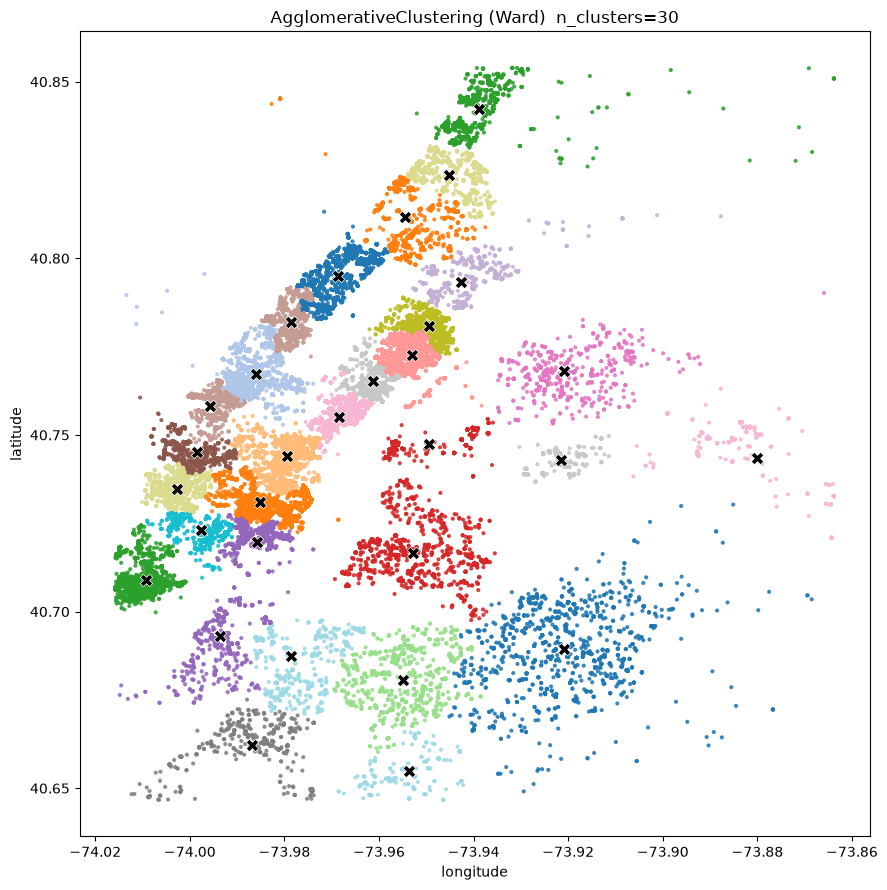

In [73]:
centers = np.array([coords_train[tr_lbl_agc == l].mean(axis=0) for l in range(N_CLUSTERS)])

plt.figure(figsize=(9, 9))
plt.scatter(coords_train[:, 0], coords_train[:, 1],
            c=tr_lbl_agc, s=4, cmap="tab20", alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=80,
            edgecolor="white", linewidth=0.5)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title(f"AgglomerativeClustering (Ward)  n_clusters={N_CLUSTERS}")
plt.tight_layout()
plt.show()

In [74]:
lasso_agc, coefs_agc, r2_agc, rmse_agc = fit_lasso_with_cluster(tr_lbl_agc, te_lbl_agc)
print(f"Agglomerative (30) + Lasso:  R2={r2_agc:.4f}  RMSE={rmse_agc:.3f}")
print("\nFeature importance (Lasso, Agglomerative):")
print(coefs_agc)

Agglomerative (30) + Lasso:  R2=0.6006  RMSE=1024.472

Feature importance (Lasso, Agglomerative):
longitude           -13381.491791
bathrooms              770.174113
bedrooms               677.758225
Doorman                553.174353
LaundryinUnit          479.732073
LaundryInBuilding     -458.110347
HardwoodFloors        -288.770698
HighSpeedInternet     -257.716525
Elevator               250.254571
DiningRoom             240.824574
cluster                233.712611
FitnessCenter          166.816957
Terrace                161.375713
NoFee                 -160.797271
LaundryinBuilding     -154.084206
RoofDeck              -120.176784
NewConstruction       -101.545239
interest_level         -99.234476
SwimmingPool            98.415274
Dishwasher              74.062270
manager_id              67.935974
Pre-War                -42.902757
OutdoorSpace           -27.343392
DogsAllowed             22.179741
CatsAllowed             -1.375003
dtype: float64


# 6. Gaussian Mixture algorithm

In [75]:
N_CLUSTERS = 30

gmm = GaussianMixture(
    n_components=N_CLUSTERS,
    covariance_type='full',
    reg_covar=1e-4,
    max_iter=300,
    random_state=21,
    init_params='kmeans'
)
gmm.fit(coords_train)

tr_lbl_gmm = gmm.predict(coords_train)
te_lbl_gmm = gmm.predict(coords_test)

print(f"n_components={N_CLUSTERS}  converged={gmm.converged_}")
print(f"Train clusters: {len(np.unique(tr_lbl_gmm))}   "
      f"Test clusters: {len(np.unique(te_lbl_gmm))}")

n_components=30  converged=True
Train clusters: 10   Test clusters: 10


In [76]:
def gmm_metrics(X, labels, means, sample_sil=2000):
    X = np.asarray(X, dtype=float)
    uniq = np.unique(labels)
    
    sse = float(((X - means[labels]) ** 2).sum())
    
    sil = float(silhouette_score(
        X, labels,
        sample_size=min(sample_sil, len(X)),
        random_state=0))
    
    return {
        "n_clusters": len(uniq),
        "distortion (SSE/n)": sse / len(X),
        "Silhouette": round(sil, 3),
    }

print("Train:", gmm_metrics(coords_train, tr_lbl_gmm, gmm.means_))
print("Test :", gmm_metrics(coords_test,  te_lbl_gmm,  gmm.means_))

Train: {'n_clusters': 10, 'distortion (SSE/n)': 0.00035975231779000836, 'Silhouette': 0.273}
Test : {'n_clusters': 10, 'distortion (SSE/n)': 0.00035907167673947607, 'Silhouette': 0.26}


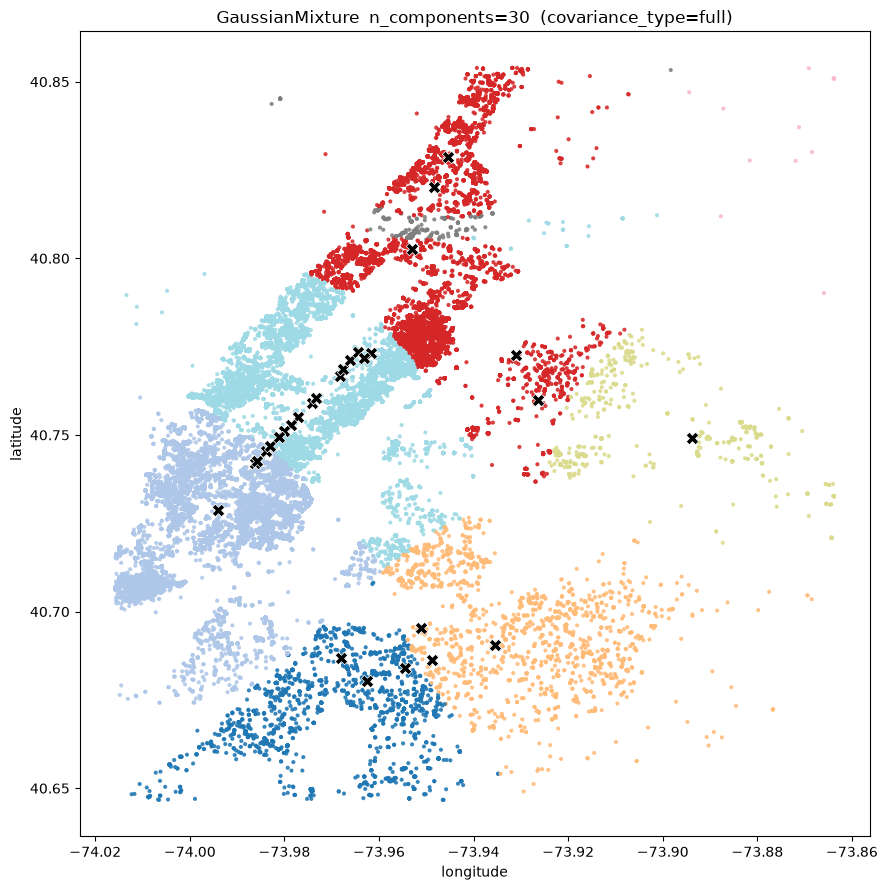

In [77]:
plt.figure(figsize=(9, 9))
plt.scatter(coords_train[:, 0], coords_train[:, 1],
            c=tr_lbl_gmm, s=4, cmap="tab20", alpha=0.8)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1],
            c="black", marker="X", s=80,
            edgecolor="white", linewidth=0.5)
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title(f"GaussianMixture  n_components={N_CLUSTERS}  "
          f"(covariance_type=full)")
plt.tight_layout()
plt.show()

In [78]:
lasso_gmm, coefs_gmm, r2_gmm, rmse_gmm = fit_lasso_with_cluster(tr_lbl_gmm, te_lbl_gmm)
print(f"GaussianMixture(30) + Lasso:  R2={r2_gmm:.4f}  RMSE={rmse_gmm:.3f}")
print("\nFeature importance (Lasso, GMM):")
print(coefs_gmm)

GaussianMixture(30) + Lasso:  R2=0.5999  RMSE=1025.304

Feature importance (Lasso, GMM):
longitude           -13764.548720
bathrooms              770.491645
bedrooms               675.275447
Doorman                520.241818
LaundryinUnit          480.932552
LaundryInBuilding     -456.227624
HardwoodFloors        -287.510158
HighSpeedInternet     -254.781756
Elevator               241.688435
DiningRoom             236.484065
FitnessCenter          170.552381
NoFee                 -165.005038
Terrace                161.184815
LaundryinBuilding     -159.253870
cluster                119.587020
RoofDeck              -116.880956
interest_level         -98.890255
NewConstruction        -94.407128
SwimmingPool            92.645003
Dishwasher              73.044612
manager_id              66.701054
Pre-War                -44.671881
OutdoorSpace           -26.646622
DogsAllowed             20.403172
dtype: float64


# 7. Different sets of features

In [79]:
FEATURE_SETS = {
    "checklist_3": ["bedrooms", "bathrooms", "interest_level"],
    "geo+checklist_3": ["longitude", "latitude", "bedrooms", "bathrooms", "interest_level"]
}

In [80]:
def prepare_cluster_data(features):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train[features].to_numpy(dtype=float))
    Xte = scaler.transform(X_test[features].to_numpy(dtype=float))
    return Xtr, Xte

In [81]:
def cluster_metrics(X, labels, sample_size=2000):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)

    mask = labels != -1
    uniq = np.unique(labels[mask])

    if len(uniq) == 0:
        return {
            "n_clusters": 0,
            "noise": 1.0,
            "sse_per_n": np.nan,
            "silhouette": np.nan
        }

    centers = np.array([X[labels == l].mean(axis=0) for l in uniq])
    lab_map = {l: i for i, l in enumerate(uniq)}
    idx = np.array([lab_map[l] for l in labels[mask]])
    sse = float(((X[mask] - centers[idx]) ** 2).sum())

    sil = np.nan
    if len(uniq) >= 2 and mask.sum() > len(uniq):
        n = min(sample_size, int(mask.sum()))
        if n <= len(uniq):
            n = None
        try:
            sil = float(silhouette_score(
                X[mask], labels[mask],
                sample_size=n,
                random_state=0
            ))
        except ValueError:
            sil = np.nan

    return {
        "n_clusters": int(len(uniq)),
        "noise": round(float((~mask).sum() / len(X)), 3),
        "sse_per_n": round(sse / len(X), 6),
        "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan
    }

In [82]:
def labels_sklearn_kmeans(Xtr, Xte, n_clusters=30):
    km = KMeans(n_clusters=n_clusters, random_state=21, n_init=10)
    tr = km.fit_predict(Xtr)
    te = km.predict(Xte)
    return tr, te

def labels_dbscan(Xtr, Xte, eps=0.3, min_samples=10):
    db = DBSCAN(eps=eps, min_samples=min_samples, algorithm="ball_tree")
    db.fit(Xtr)
    tr = db.labels_
    te = dbscan_assign(db, Xte)
    return tr, te

def labels_agglomerative(Xtr, Xte, n_clusters=30):
    n_neighbors = min(15, len(Xtr) - 1)
    connectivity = kneighbors_graph(
        Xtr, n_neighbors=n_neighbors, include_self=False
    )
    agc = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage="ward",
        connectivity=connectivity
    )
    tr = agc.fit_predict(Xtr)
    knn = KNeighborsClassifier(n_neighbors=1, algorithm="ball_tree")
    knn.fit(Xtr, tr)
    te = knn.predict(Xte)
    return tr, te

def labels_gmm(Xtr, Xte, n_clusters=30):
    gm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=21,
        n_init=1
    )
    tr = gm.fit_predict(Xtr)
    te = gm.predict(Xte)
    return tr, te

In [83]:
def run_one(feature_set_name, features, algorithm_name, label_fn, params):
    Xtr, Xte = prepare_cluster_data(features)
    tr_lbl, te_lbl = label_fn(Xtr, Xte, **params)   
    m = cluster_metrics(Xtr, tr_lbl)    
    if m["n_clusters"] < 2:
        return None
    if np.sum(te_lbl != -1) == 0:
        return None 
    _, _, r2, rmse = fit_lasso_with_cluster(tr_lbl, te_lbl) 
    row = {
        "feature_set": feature_set_name,
        "features": "+".join(features),
        "algorithm": algorithm_name,
        "params": str(params),
        "n_clusters": m["n_clusters"],
        "noise": m["noise"],
        "sse_per_n": m["sse_per_n"],
        "silhouette": m["silhouette"],
        "Lasso_R2": round(float(r2), 4),
        "Lasso_RMSE": round(float(rmse), 3),
    }
    return row

In [84]:
K_GRID = [4, 6, 8, 10, 15, 30]

DBSCAN_GRID = [
    (eps, ms)
    for eps in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]
    for ms in [5, 10, 20]
]

In [85]:
results = []

for set_name, features in FEATURE_SETS.items():
    print(f"Feature set: {set_name} = {features}")

    for k in K_GRID:
        for alg_name, label_fn in [
            ("sklearn_kmeans", labels_sklearn_kmeans),
            ("agglomerative", labels_agglomerative),
            ("gmm", labels_gmm),
        ]:
            row = run_one(
                set_name, features,
                alg_name, label_fn,
                {"n_clusters": k}
            )
            if row is not None:
                results.append(row)
                print(row)

    for eps, ms in DBSCAN_GRID:
        row = run_one(
            set_name, features,
            "dbscan", labels_dbscan,
            {"eps": eps, "min_samples": ms}
        )
        if row is not None:
            results.append(row)
            print(row)

res_features = pd.DataFrame(results)

best_per_alg = (
    res_features
    .sort_values("Lasso_R2", ascending=False)
    .groupby(["feature_set", "algorithm"])
    .head(1)
    .sort_values(["feature_set", "Lasso_R2"], ascending=[True, False])
)

display(best_per_alg)

Feature set: checklist_3 = ['bedrooms', 'bathrooms', 'interest_level']
{'feature_set': 'checklist_3', 'features': 'bedrooms+bathrooms+interest_level', 'algorithm': 'sklearn_kmeans', 'params': "{'n_clusters': 4}", 'n_clusters': 4, 'noise': 0.0, 'sse_per_n': 1.163561, 'silhouette': 0.451, 'Lasso_R2': 0.6115, 'Lasso_RMSE': 1010.283}
{'feature_set': 'checklist_3', 'features': 'bedrooms+bathrooms+interest_level', 'algorithm': 'agglomerative', 'params': "{'n_clusters': 4}", 'n_clusters': 4, 'noise': 0.0, 'sse_per_n': 1.277385, 'silhouette': 0.393, 'Lasso_R2': 0.599, 'Lasso_RMSE': 1026.468}
{'feature_set': 'checklist_3', 'features': 'bedrooms+bathrooms+interest_level', 'algorithm': 'gmm', 'params': "{'n_clusters': 4}", 'n_clusters': 4, 'noise': 0.0, 'sse_per_n': 1.257441, 'silhouette': 0.442, 'Lasso_R2': 0.6036, 'Lasso_RMSE': 1020.528}
{'feature_set': 'checklist_3', 'features': 'bedrooms+bathrooms+interest_level', 'algorithm': 'sklearn_kmeans', 'params': "{'n_clusters': 6}", 'n_clusters': 6, 

,feature_set,features,algorithm,params,n_clusters,noise,sse_per_n,silhouette,Lasso_R2,Lasso_RMSE
34,checklist_3,bedrooms+bathrooms+interest_level,dbscan,"{'eps': 0.8, 'min_samples': 10}",85,0.002,0.000000,0.995,0.6161,1004.320
0,checklist_3,bedrooms+bathrooms+interest_level,sklearn_kmeans,{'n_clusters': 4},4,0.000,1.163561,0.451,0.6115,1010.283
8,checklist_3,bedrooms+bathrooms+interest_level,gmm,{'n_clusters': 8},8,0.000,0.763196,0.580,0.6044,1019.514
16,checklist_3,bedrooms+bathrooms+interest_level,agglomerative,{'n_clusters': 30},30,0.000,0.058185,0.926,0.6019,1022.701
39,geo+checklist_3,longitude+latitude+bedrooms+bathrooms+interest...,sklearn_kmeans,{'n_clusters': 4},4,0.000,2.898827,0.261,0.6185,1001.150
72,geo+checklist_3,longitude+latitude+bedrooms+bathrooms+interest...,dbscan,"{'eps': 0.8, 'min_samples': 5}",125,0.006,1.889764,0.001,0.6130,1008.372
43,geo+checklist_3,longitude+latitude+bedrooms+bathrooms+interest...,agglomerative,{'n_clusters': 6},6,0.000,2.541483,0.182,0.6107,1011.346
41,geo+checklist_3,longitude+latitude+bedrooms+bathrooms+interest...,gmm,{'n_clusters': 4},4,0.000,3.448657,0.234,0.6095,1012.994


Вывод: Наилучшее качество Lasso показал DBSCAN . Однако метрики указывают на то, что алгоритм создал микрокластеры вокруг конкретных комбинаций значений. Среди алгоритмов, требующих указания числа кластеров, лучший результат у K-Means, что говорит о наличии 4-х основных групп в распределении комнат и интереса. Добавление координат немного улучшило метрику Lasso для K-Means.

# 8. Additional task

In [86]:
km = KMeans(n_clusters=4, random_state=21, n_init=10)
tr_lbl = km.fit_predict(coords_train)
te_lbl = km.predict(coords_test)

X_tr_model = Xtr_base.copy()
X_te_model = Xte_base.copy()
X_tr_model["cluster"] = tr_lbl
X_te_model["cluster"] = te_lbl

mms = MinMaxScaler()
X_tr_model[["cluster"]] = mms.fit_transform(X_tr_model[["cluster"]])
X_te_model[["cluster"]] = mms.transform(X_te_model[["cluster"]])

models = {
    "Ridge": Ridge(alpha=1.0),
    "ElasticNet": ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=21),
    "RandomForest": RandomForestRegressor(n_estimators=50, max_depth=10, random_state=21)
}

In [87]:
for name, model in models.items():
    model.fit(X_tr_model, y_train)
    pred = model.predict(X_te_model)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name} | R2: {r2:.4f} | RMSE: {rmse:.1f}")

features_3 = ["bedrooms", "bathrooms", "interest_level"]
scaler = StandardScaler()
X_3_tr = scaler.fit_transform(X_train[features_3])
X_3_te = scaler.transform(X_test[features_3])

Ridge | R2: 0.6007 | RMSE: 1024.3
ElasticNet | R2: 0.4483 | RMSE: 1204.0
RandomForest | R2: 0.7745 | RMSE: 769.8


In [88]:
for k in range(2, 21):
    km_k = KMeans(n_clusters=k, random_state=21, n_init=10)
    tr_l = km_k.fit_predict(X_3_tr)
    te_l = km_k.predict(X_3_te)
    
    sil = silhouette_score(X_3_tr, tr_l, sample_size=2000, random_state=0)
    
    X_tr_k = Xtr_base.copy()
    X_te_k = Xte_base.copy()
    X_tr_k["cluster"] = tr_l
    X_te_k["cluster"] = te_l
    X_tr_k[["cluster"]] = mms.fit_transform(X_tr_k[["cluster"]])
    X_te_k[["cluster"]] = mms.transform(X_te_k[["cluster"]])
    
    las = Lasso(alpha=1.0, max_iter=5000, random_state=21)
    las.fit(X_tr_k, y_train)
    r2 = r2_score(y_test, las.predict(X_te_k))
    
    print(f"k = {k} | Silhouette: {sil:.3f} | Lasso R2: {r2:.4f}")

k = 2 | Silhouette: 0.418 | Lasso R2: 0.6031
k = 3 | Silhouette: 0.446 | Lasso R2: 0.6067
k = 4 | Silhouette: 0.451 | Lasso R2: 0.6115
k = 5 | Silhouette: 0.489 | Lasso R2: 0.6050
k = 6 | Silhouette: 0.521 | Lasso R2: 0.5986
k = 7 | Silhouette: 0.551 | Lasso R2: 0.6018
k = 8 | Silhouette: 0.584 | Lasso R2: 0.5989
k = 9 | Silhouette: 0.658 | Lasso R2: 0.5988
k = 10 | Silhouette: 0.687 | Lasso R2: 0.5998
k = 11 | Silhouette: 0.696 | Lasso R2: 0.6003
k = 12 | Silhouette: 0.743 | Lasso R2: 0.6006
k = 13 | Silhouette: 0.727 | Lasso R2: 0.5991
k = 14 | Silhouette: 0.763 | Lasso R2: 0.5995
k = 15 | Silhouette: 0.819 | Lasso R2: 0.5988
k = 16 | Silhouette: 0.833 | Lasso R2: 0.5988
k = 17 | Silhouette: 0.844 | Lasso R2: 0.6005
k = 18 | Silhouette: 0.843 | Lasso R2: 0.5991
k = 19 | Silhouette: 0.848 | Lasso R2: 0.5986
k = 20 | Silhouette: 0.868 | Lasso R2: 0.5981


In [89]:
tr_km = KMeans(n_clusters=4, random_state=21, n_init=10).fit_predict(coords_train)

db = DBSCAN(eps=0.005, min_samples=10, algorithm="ball_tree").fit(coords_train)
tr_db = db.labels_

conn = kneighbors_graph(coords_train, n_neighbors=10, include_self=False)
tr_agg = AgglomerativeClustering(n_clusters=4, connectivity=conn, linkage='ward').fit_predict(coords_train)

tr_gmm = GaussianMixture(n_components=4, random_state=21).fit_predict(coords_train)

In [90]:
X_combined = Xtr_base.copy()
X_combined["cluster_km"] = tr_km
X_combined["cluster_db"] = tr_db
X_combined["cluster_agg"] = tr_agg
X_combined["cluster_gmm"] = tr_gmm

selector = SelectKBest(score_func=f_regression, k=15)
X_selected = selector.fit_transform(X_combined, y_train)

selected_cols = X_combined.columns[selector.get_support()]
print("Оставленные признаки:")
for col in selected_cols:
    print("-", col)

Оставленные признаки:
- bathrooms
- bedrooms
- longitude
- Elevator
- Doorman
- Dishwasher
- LaundryinBuilding
- FitnessCenter
- LaundryinUnit
- OutdoorSpace
- DiningRoom
- Balcony
- SwimmingPool
- Terrace
- cluster_gmm
